# Step #1 Load Time Series Data

In [ ]:
# A tutorial for this file is available at www.relataly.com
# Tested with Python 3.12, pandas 3.0, statsmodels 0.14, and pmdarima 2.1

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pmdarima as pm
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import seasonal_decompose

sns.set_theme(style="white", rc={"axes.spines.right": False, "axes.spines.top": False})

# Originally published at:
# https://www.kaggle.com/datasets/bulentsiyah/for-simple-exercises-time-series-forecasting
relative_data_path = Path("data/alcohol_sales/BeerWineLiquor.csv")
data_path = next(
    path / relative_data_path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / relative_data_path).exists()
)
df = pd.read_csv(data_path, parse_dates=["date"], date_format="%m/%d/%Y")
df.head()

,date,beer
0,1992-01-01,1509
1,1992-02-01,1541
2,1992-03-01,1597
3,1992-04-01,1675
4,1992-05-01,1822


# Step #2 Visualize the Time-Series and Check it for Stationarity

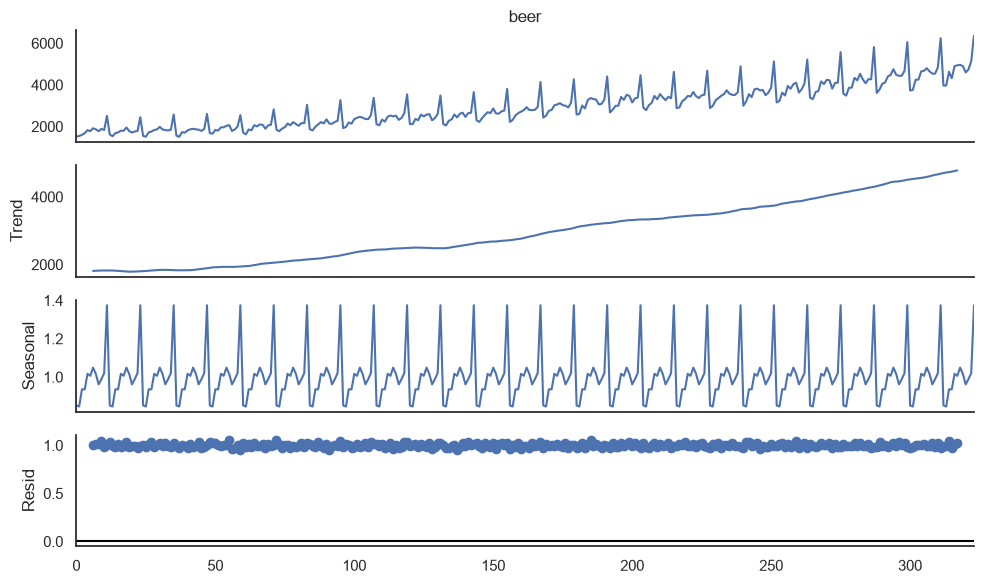

In [4]:
# Decompose the time series
plt.rcParams["figure.figsize"] = (10,6)
result = seasonal_decompose(df['beer'], model='multiplicative', period = 12)
result.plot()
plt.show()

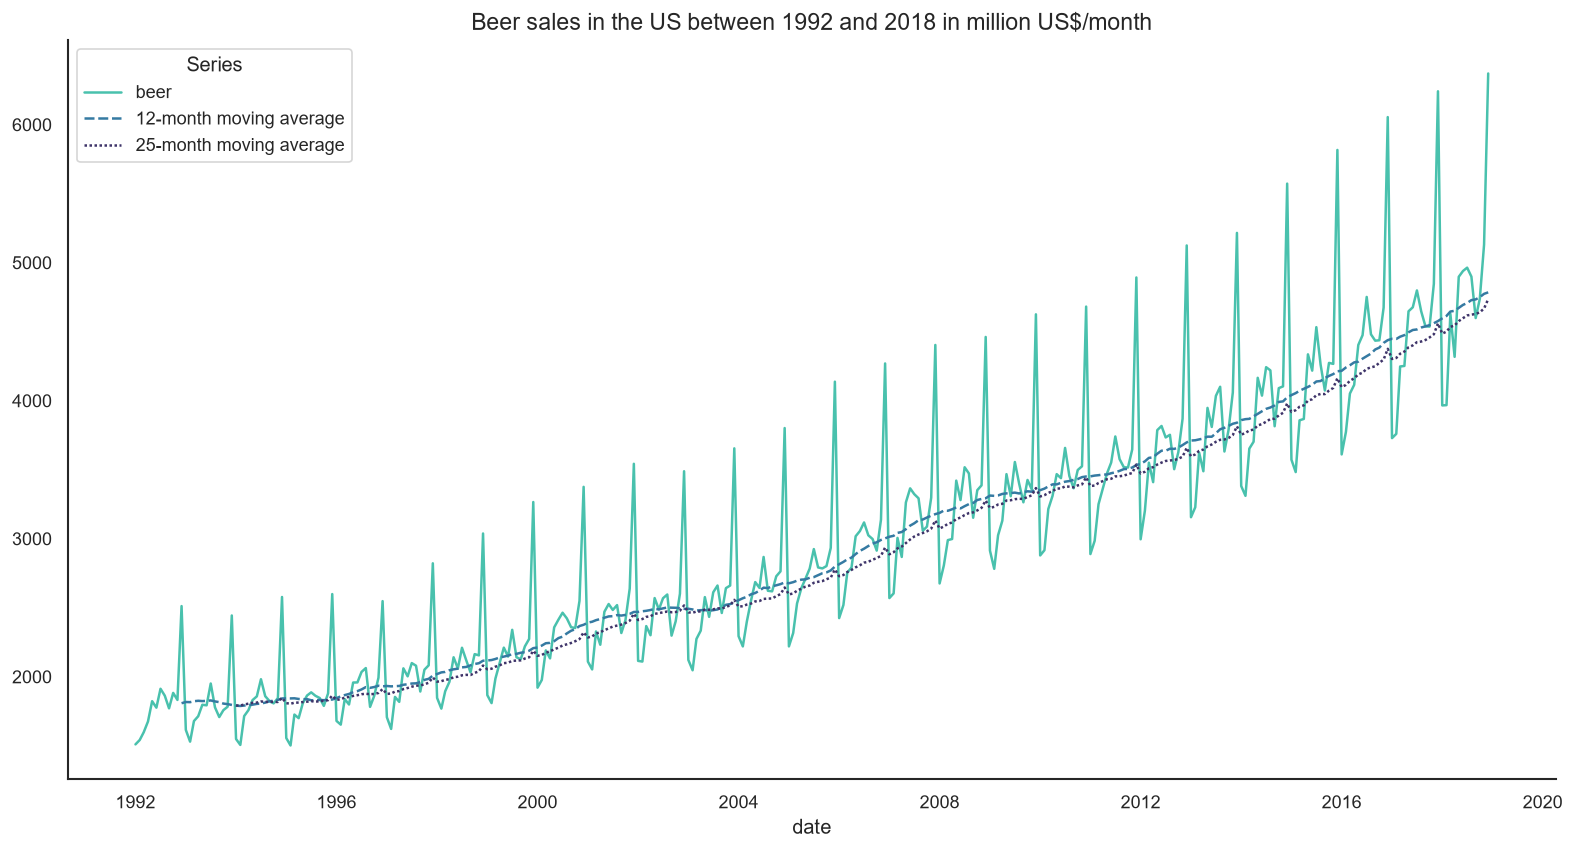

ADF p-value: 0.0191; should difference: False


In [ ]:
def check_stationarity(sales, title_string):
    sales = sales.dropna().rename("beer")
    plot_data = sales.to_frame()

    if sales.size > 12:
        plot_data["12-month moving average"] = sales.rolling(window=12).mean()
        plot_data["25-month moving average"] = sales.rolling(window=25).mean()

    _, ax = plt.subplots(figsize=(16, 8))
    sns.lineplot(data=plot_data, ax=ax, palette=sns.color_palette("mako_r", plot_data.shape[1]))
    ax.set_title(title_string, fontsize=14)
    ax.legend(title="Series", loc="upper left")
    plt.show()

    # ADFTest returns the p-value and whether differencing is recommended at alpha=0.05.
    adf_test = pm.arima.ADFTest(alpha=0.05)
    p_value, should_difference = adf_test.should_diff(sales)
    print(f"ADF p-value: {p_value:.4f}; should difference: {should_difference}")


df_sales = df.set_index("date")[["beer"]].sort_index().asfreq("MS")
title = "Beer sales in the US between 1992 and 2018 in million US$/month"
check_stationarity(df_sales["beer"], title)

# Step #3 Exemplary Differencing and Autocorrelation

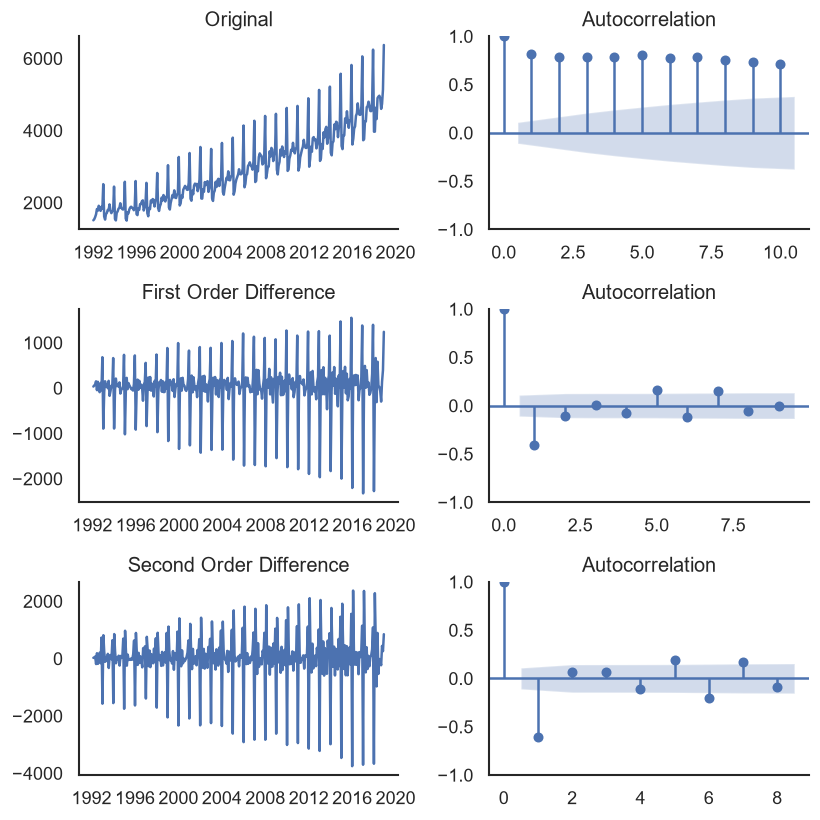

In [ ]:
# 3.1 Non-seasonal part
def auto_correlation(df, prefix, lags):
    plt.rcParams.update({'figure.figsize':(7,7), 'figure.dpi':120})
    
    # Define the plot grid
    _, axes = plt.subplots(3,2, sharex=False)

    # Original series
    axes[0, 0].plot(df)
    axes[0, 0].set_title('Original' + prefix)
    plot_acf(df, lags=lags, ax=axes[0, 1])

    # First Difference
    df_first_diff = df.diff().dropna()
    axes[1, 0].plot(df_first_diff)
    axes[1, 0].set_title('First Order Difference' + prefix)
    plot_acf(df_first_diff, lags=lags - 1, ax=axes[1, 1])

    # Second Difference
    df_second_diff = df.diff().diff().dropna()
    axes[2, 0].plot(df_second_diff)
    axes[2, 0].set_title('Second Order Difference' + prefix)
    plot_acf(df_second_diff, lags=lags - 2, ax=axes[2, 1])
    plt.tight_layout()
    plt.show()
    
auto_correlation(df_sales['beer'], '', 10)

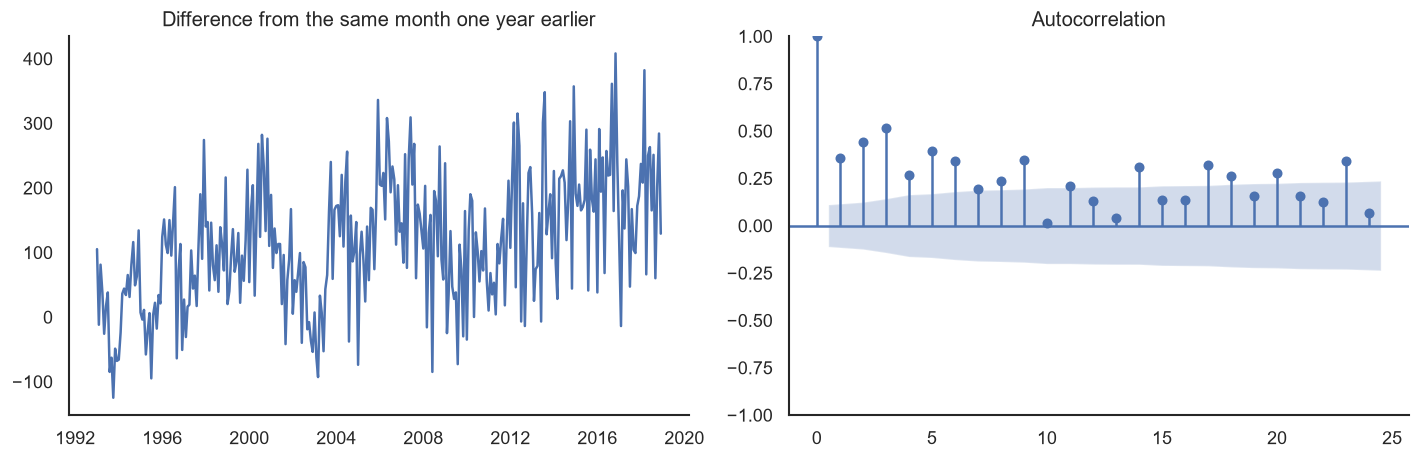

In [15]:
# 3.2 Seasonal differencing
seasonal_lag = 12
seasonal_difference = df_sales["beer"].diff(seasonal_lag).dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(seasonal_difference)
axes[0].set_title("Difference from the same month one year earlier")
plot_acf(seasonal_difference, lags=24, ax=axes[1])
plt.tight_layout()
plt.show()

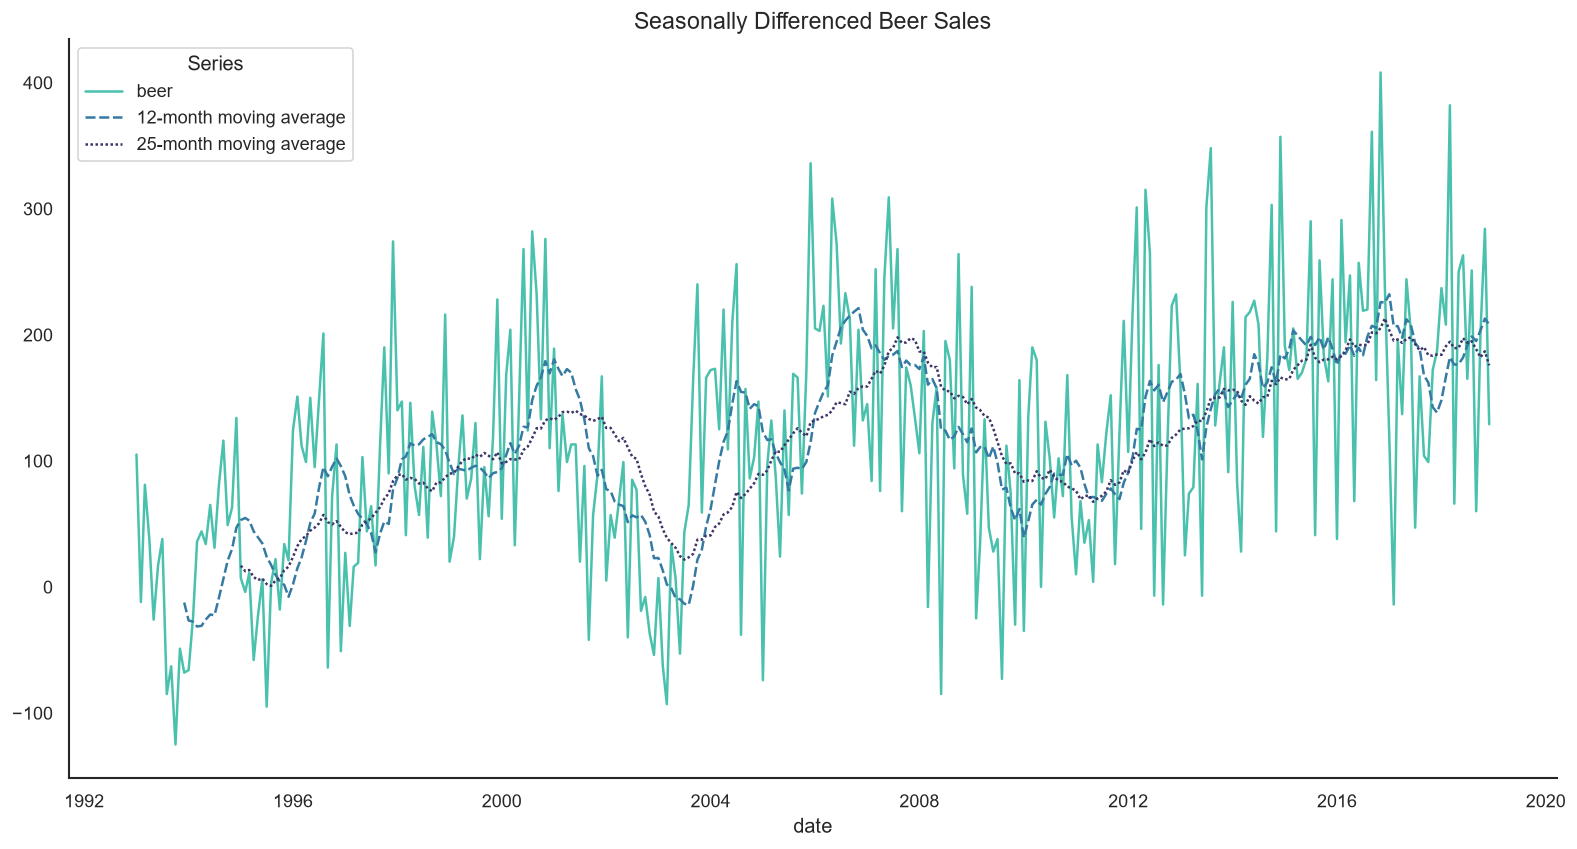

ADF p-value: 0.0100; should difference: False


In [16]:
# Test the lag-12 seasonal difference for a remaining unit root.
check_stationarity(seasonal_difference, "Seasonally Differenced Beer Sales")

# Step #4 Finding an Optimal Model with Auto-ARIMA

In [20]:
# Reserve the final 30 months as an untouched test set.
pred_periods = 30
split_number = len(df_sales) - pred_periods
df_train = df_sales.iloc[:split_number].rename(columns={"beer": "y_train"}).copy()
df_test = df_sales.iloc[split_number:].rename(columns={"beer": "y_test"}).copy()

model_fit = pm.auto_arima(
    df_train["y_train"],
    test="adf",
    max_p=3,
    max_d=3,
    max_q=3,
    seasonal=True,
    m=12,
    max_P=3,
    max_D=2,
    max_Q=3,
    trace=True,
    error_action="ignore",
    suppress_warnings=True,
    stepwise=True,
)

print(model_fit.summary())

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[12] intercept   : AIC=inf, Time=2.35 sec
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=3383.210, Time=0.03 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=3351.655, Time=0.22 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=3364.350, Time=0.61 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=3604.145, Time=0.03 sec
 ARIMA(1,0,0)(0,1,0)[12] intercept   : AIC=3349.908, Time=0.10 sec
 ARIMA(1,0,0)(0,1,1)[12] intercept   : AIC=3351.532, Time=0.19 sec
 ARIMA(1,0,0)(1,1,1)[12] intercept   : AIC=3353.520, Time=0.75 sec
 ARIMA(2,0,0)(0,1,0)[12] intercept   : AIC=3312.656, Time=0.10 sec
 ARIMA(2,0,0)(1,1,0)[12] intercept   : AIC=3314.483, Time=0.31 sec
 ARIMA(2,0,0)(0,1,1)[12] intercept   : AIC=3314.378, Time=0.20 sec
 ARIMA(2,0,0)(1,1,1)[12] intercept   : AIC=3305.552, Time=1.23 sec
 ARIMA(2,0,0)(2,1,1)[12] intercept   : AIC=3291.425, Time=3.22 sec
 ARIMA(2,0,0)(2,1,0)[12] intercept   : AIC=3306.914, Time=2.47 sec
 ARIMA(2,0,0)(3,1,1)[12]

# Step #5 Simulate the Time Series with in-sample Forecasting

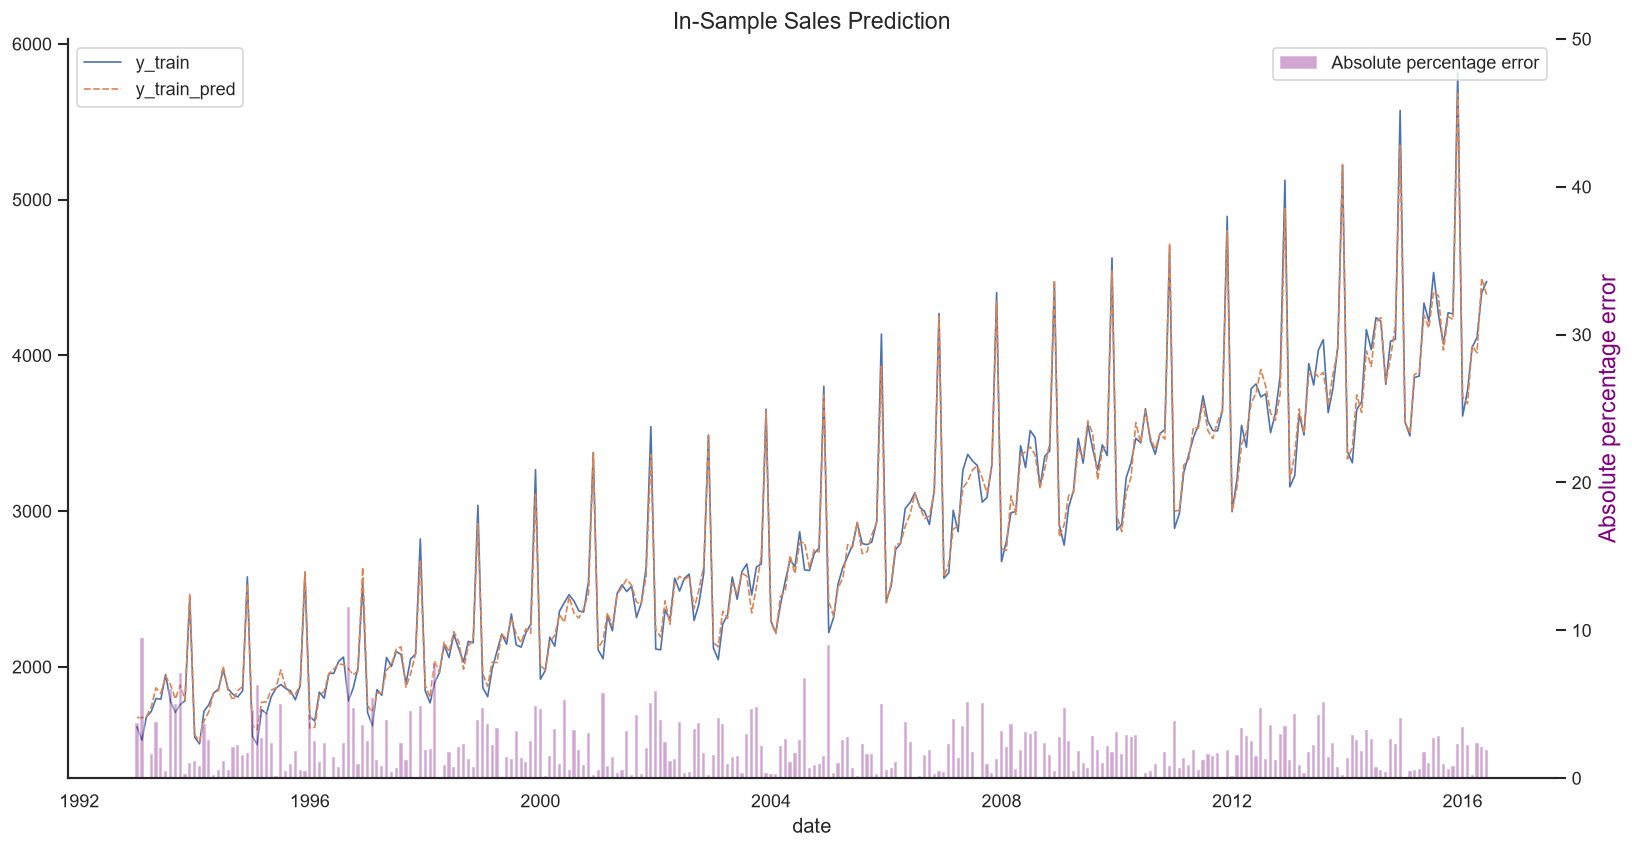

In [21]:
# Generate one-step-ahead in-sample predictions.
in_sample_prediction = model_fit.predict_in_sample(dynamic=False)
df_train["y_train_pred"] = in_sample_prediction

df_train["absolute_percentage_error"] = (
    (df_train["y_train"] - df_train["y_train_pred"]).abs() / df_train["y_train"] * 100
)

# Skip the first seasonal cycle, where model initialization dominates the fitted values.
plot_data = df_train.iloc[12:]
fig, ax1 = plt.subplots(figsize=(16, 8))
sns.lineplot(data=plot_data[["y_train", "y_train_pred"]], ax=ax1, linewidth=1.0)
ax1.set_title("In-Sample Sales Prediction", fontsize=14)

ax2 = ax1.twinx()
ax2.set_ylabel("Absolute percentage error", color="purple", fontsize=14)
ax2.set_ylim(0, 50)
ax2.bar(
    plot_data.index,
    plot_data["absolute_percentage_error"],
    width=20,
    color="purple",
    alpha=0.35,
    label="Absolute percentage error",
)
ax2.legend(loc="upper right")
plt.show()

# Step #6 Generate and Visualize a Sales Forecast

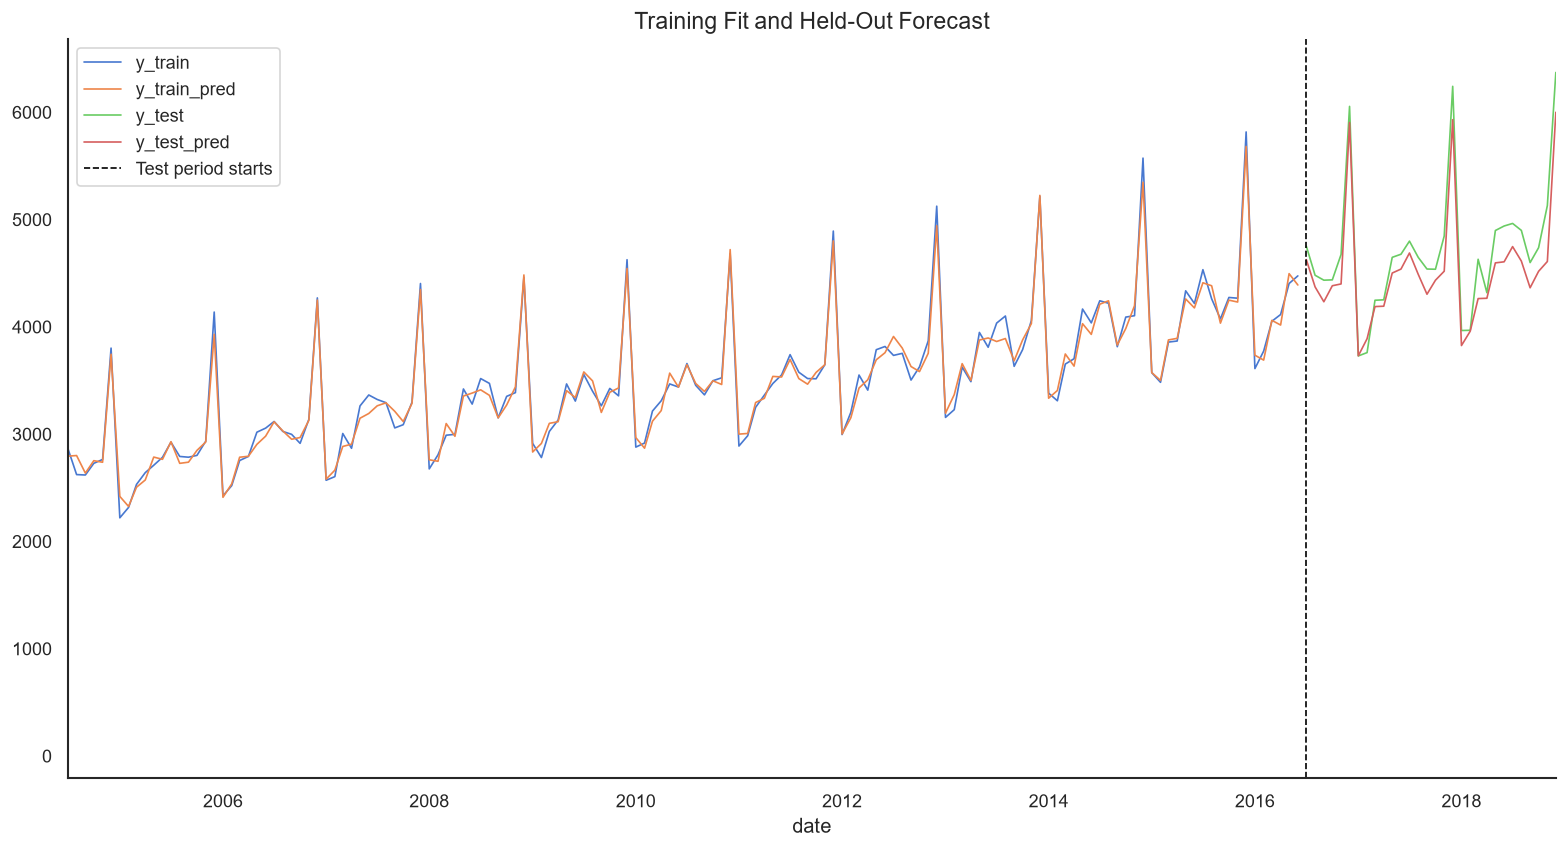

In [22]:
# Forecast the held-out 30 months after the end of the training data.
df_test["y_test_pred"] = model_fit.predict(n_periods=pred_periods)
df_union = pd.concat([df_train, df_test])

fig, ax = plt.subplots(figsize=(16, 8))
sns.lineplot(
    data=df_union[["y_train", "y_train_pred", "y_test", "y_test_pred"]],
    ax=ax,
    linewidth=1.0,
    dashes=False,
    palette="muted",
)
ax.axvline(df_test.index[0], color="black", linestyle="--", linewidth=1, label="Test period starts")
ax.set_title("Training Fit and Held-Out Forecast", fontsize=14)
ax.set_xlim(df_union.index[150], df_union.index.max())
ax.legend()
sns.despine()
plt.show()

# Step #7 Measure Performance

In [23]:
absolute_percentage_errors = (
    (df_test["y_test"] - df_test["y_test_pred"]).abs() / df_test["y_test"] * 100
)
mape = absolute_percentage_errors.mean()
median_ape = absolute_percentage_errors.median()

print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"Median Absolute Percentage Error: {median_ape:.2f}%")

Mean Absolute Percentage Error (MAPE): 3.94%
Median Absolute Percentage Error: 3.49%
